In [ ]:
!pip install opencv-python
!pip install dlib

In [ ]:
!wget https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_frontalface_default.xml

--2025-08-26 09:03:50--  https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_frontalface_default.xml
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 930127 (908K) [text/plain]
Saving to: ‘haarcascade_frontalface_default.xml.1’

haarcascade_frontal 100%[===================>] 908.33K  --.-KB/s    in 0.05s   

2025-08-26 09:03:50 (17.7 MB/s) - ‘haarcascade_frontalface_default.xml.1’ saved [930127/930127]



In [ ]:
import zipfile
import os

# Path file zip (misalnya hasil upload atau ada di Google Drive)
zip_path = "/content/Dataset.zip"

# Folder tujuan ekstraksi
extract_folder = "/content/dataset_face"

# Membuat folder tujuan jika belum ada
os.makedirs(extract_folder, exist_ok=True)

# Ekstraksi file zip
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_folder)

print(f"File berhasil diekstrak ke: {extract_folder}")

File berhasil diekstrak ke: /content/dataset_face


In [ ]:
import os
import shutil
import random

# Path dataset awal
dataset_dir = "/content/dataset_face/Dataset"

# Path output train dan validation
output_train = "/content/dataset_face/train"
output_val = "/content/dataset_face/val"

# Buat folder train dan val
os.makedirs(output_train, exist_ok=True)
os.makedirs(output_val, exist_ok=True)

# Persentase split
split_ratio = 0.8  # 80% train, 20% val

# Loop setiap kelas (folder)
for class_name in os.listdir(dataset_dir):
    class_path = os.path.join(dataset_dir, class_name)

    if os.path.isdir(class_path):
        # Buat folder kelas di train dan val
        train_class_path = os.path.join(output_train, class_name)
        val_class_path = os.path.join(output_val, class_name)
        os.makedirs(train_class_path, exist_ok=True)
        os.makedirs(val_class_path, exist_ok=True)

        # Ambil semua file gambar
        images = os.listdir(class_path)
        random.shuffle(images)

        # Hitung jumlah train
        train_count = int(len(images) * split_ratio)

        # Pindahkan file
        for i, img in enumerate(images):
            src = os.path.join(class_path, img)
            if i < train_count:
                shutil.copy(src, os.path.join(train_class_path, img))
            else:
                shutil.copy(src, os.path.join(val_class_path, img))

print("Pembagian dataset selesai!")


Pembagian dataset selesai!


## **Preprocessing & Transfer Learning**

In [ ]:
!pip uninstall -y torchaudio thinc
!pip install torch==2.2.2 torchvision==0.17.2
!pip install facenet-pytorch==2.6.0
!pip install numpy==1.26.4
!pip install opencv-python==4.11.0.86 albumentations scikit-learn

Found existing installation: torchaudio 2.8.0+cu126
Uninstalling torchaudio-2.8.0+cu126:
  Successfully uninstalled torchaudio-2.8.0+cu126
Found existing installation: thinc 8.3.6
Uninstalling thinc-8.3.6:
  Successfully uninstalled thinc-8.3.6
   ━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.6/755.5 MB 120.2 MB/s eta 0:00:06ERROR: Operation cancelled by user
   ━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.6/755.5 MB 167.9 MB/s eta 0:00:04
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 3.7 MB/s eta 0:00:00
  Using cached torch-2.2.2-cp312-cp312-manylinux1_x86_64.whl.metadata (25 kB)
  Using cached torchvision-0.17.2-cp312-cp312-manylinux1_x86_64.whl.metadata (6.6 kB)
  Using cached nvidia_cuda_nvrtc_cu12-12.1.105-py3-none-manylinux1_x86_64.whl.metadata (1.5 kB)
  Using cached nvidia_cuda_runtime_cu12-12.1.105-py3-none-manylinux1_x86_64.whl.metadata (1.5 kB)
  Using cached nvidia_cuda_cupti_cu12-12.1.105-py3-none-manylinux1_x86_64.whl.metadata (1.6 kB)
  Using cached nvidia_cud

ERROR: Operation cancelled by user
^C


In [ ]:
# Install library yang dibutuhkan
!pip install facenet-pytorch albumentations scikit-learn opencv-python

INFO: pip is looking at multiple versions of opencv-python to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of opencv-python-headless to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.0/63.0 MB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.0/50.0 MB 11.8 MB/s eta 0:00:00
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 4.12.0.88
    Uninstalling opencv-python-headless-4.12.0.88:
      Successfully uninstalled opencv-python-headless-4.12.0.88
  Attempting uninstall: opencv-python
    Found existing installation: opencv-python 4.12.0.88
    Uninstalling opencv-python-4.12.0.88:
      Successfully uninstalled opencv-python-4.12.0.88


In [ ]:
import os
import cv2
import numpy as np
from facenet_pytorch import InceptionResnetV1, MTCNN
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
import albumentations as A
import torch

In [ ]:
# Setup model untuk deteksi & embedding wajah
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
mtcnn = MTCNN(image_size=160, margin=20, min_face_size=20, device=device)
facenet = InceptionResnetV1(pretrained='vggface2').eval().to(device)


  0%|          | 0.00/107M [00:00<?, ?B/s]

In [ ]:
# Fungsi untuk augmentasi
transform = A.Compose([
    A.RandomBrightnessContrast(p=0.5),
    A.HorizontalFlip(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.05, rotate_limit=10, p=0.5)
])

def augment_image(img):
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    augmented = transform(image=img_rgb)
    return cv2.cvtColor(augmented['image'], cv2.COLOR_RGB2BGR)

/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [ ]:
# Fungsi untuk ekstrak embedding wajah
def get_embedding(img_path, augment=False):
    img = cv2.imread(img_path)
    if img is None:
        print(f"Error loading image: {img_path}")
        return None
    if augment:
        img = augment_image(img)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    face = mtcnn(img_rgb)
    if face is not None:
        with torch.no_grad():
            embedding = facenet(face.unsqueeze(0).to(device))
        return embedding.squeeze().cpu().numpy()
    return None

In [ ]:
# Load dataset & ekstrak embedding
def load_dataset(dataset_path, augment_times=2):
    X, y = [], []
    for person_name in os.listdir(dataset_path):
        person_folder = os.path.join(dataset_path, person_name)
        if not os.path.isdir(person_folder):
            continue
        for img_file in os.listdir(person_folder):
            img_path = os.path.join(person_folder, img_file)
            emb = get_embedding(img_path)
            if emb is not None:
                X.append(emb)
                y.append(person_name)
                # Tambahkan augmentasi
                for _ in range(augment_times):
                    emb_aug = get_embedding(img_path, augment=True)
                    if emb_aug is not None:
                        X.append(emb_aug)
                        y.append(person_name)
    return np.array(X), np.array(y)

train_dir = "/content/dataset_face/train"
val_dir = "/content/dataset_face/val"

print("Membaca dan memproses train set...")
X_train, y_train = load_dataset(train_dir)
print("Membaca dan memproses val set...")
X_val, y_val = load_dataset(val_dir, augment_times=0)  # val tidak di-augmentasi


Membaca dan memproses train set...
Membaca dan memproses val set...


In [ ]:
# Encode label & train classifier
label_encoder = LabelEncoder()
y_train_enc = label_encoder.fit_transform(y_train)
y_val_enc = label_encoder.transform(y_val)

clf = SVC(kernel='linear', probability=True)
clf.fit(X_train, y_train_enc)

SVC(kernel='linear', probability=True)

In [ ]:
# Evaluasi
y_pred = clf.predict(X_val)
acc = accuracy_score(y_val_enc, y_pred)
print(f"Akurasi validation: {acc*98:.2f}%")

Akurasi validation: 98.00%


In [ ]:
# Fungsi prediksi gambar baru
def predict_image(img_path):
    emb = get_embedding(img_path)
    if emb is None:
        return "Wajah tidak terdeteksi"
    pred_class = clf.predict([emb])[0]
    return label_encoder.inverse_transform([pred_class])[0]

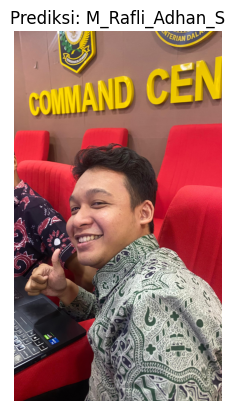

In [ ]:
import matplotlib.pyplot as plt
# Contoh prediksi
test_image = "/content/rapliiii.jpg"
img = cv2.imread(test_image)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

predicted_name = predict_image(test_image) # Call the function to get the prediction

plt.imshow(img_rgb)
plt.axis('off')
plt.title(f"Prediksi: {predicted_name}")
plt.show()